# Examples, Summer 2024.
#### to be run independently except for cells A and B (init and input).
-----------

## A. Init

In [ ]:
import sys
sys.path.append('../Code/')
from imports import *
%load_ext autoreload
%autoreload 2
rc("font", **{"family": "serif", "serif": ["Times"]})
rc("text", usetex=True)
# note: if your jupyter notebook doesn't like importing namespaces from local files, 
# you can add ```imports``` as an extra path to get rid of the annoying red squiggly line.

import csv


## B. Input

In [ ]:
# Example usage:
seed = 10
M, N = chf.generate_random_rectangles(1, 2, seed=seed)
# or 
M , N = ex.test_ex_more_rects()

# Call the function to plot rectangles
chf.plot_rectangles(M,N)


## Experiment 1: With/without prune


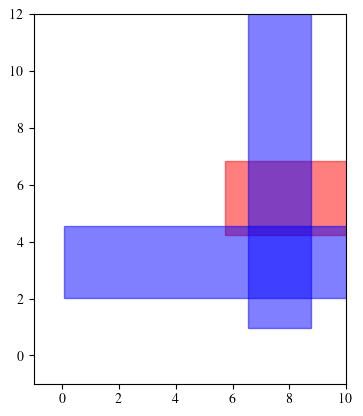

Rectangles in M: 1 and N: 2. Total: 3.
PRUNE POINTS
______________________________________
3v1: Computed 1137 pts; 514 deduplicated
-------------
2v2paired: Computed 134 pts; 113 deduplicated
-------------
2v2unpaired: Computed 205 pts; 178 deduplicated
______________________________________
Matching dist: 1.2990969986369292 with slope (1.0, 0.986231323116747) and intercept (1.5771601280146035, -1.5771601280146035).
Time elapsed: 15.77 sec


DON'T PRUNE POINTS
______________________________________
3v1: Computed 4892 pts; 1218 deduplicated
-------------
2v2paired: Computed 134 pts; 113 deduplicated
-------------
2v2unpaired: Computed 1747 pts; 558 deduplicated
______________________________________
Matching dist: 1.2990969986369292 with slope (1.0, 0.986231323116747) and intercept (1.5771601280146035, -1.5771601280146035).
Time elapsed: 74.21 sec

Approximate Matching Distance:
Maximum distance for lines through critical points: 1.27
Maximum distance computed for grid of lines: 1.30
Ti

In [53]:
# NOTE: we are only doing this for bigger examples, 
# not those with just one rectangle per module, at least for now

# prune by default true
# what we want: 
# prune TRUE means let algo decide if take the thing
# prune FALSE means always return all the things

# Example usage:
rects_in_M = 1
rects_in_N = 2
seed = 10
M, N = chf.generate_random_rectangles(rects_in_M,rects_in_N, seed=seed)

chf.plot_rectangles(M,N)
prune_time, no_prune_time, approx_time, prune_match_dist, no_prune_match_dist, max_dist_critpts, max_grids_lines = chf.to_prune_or_not_to_prune_csv(M,N)

data = {
    "Label":"Run 11",
  "rects in M": rects_in_M,
  "rects in N": rects_in_N,
  "seed": seed,
  "Prune Matching dist": prune_match_dist,
  "No Prune Matching dist": no_prune_match_dist,
  "Approx Matching dist through cps": max_dist_critpts,
  "Approx Matching dist grid":max_grids_lines ,
  "Time Prune" :prune_time,
  "Time No Prune": no_prune_time,
  "Time Approx": approx_time

}
file_path = '../output/dict.csv'


# # FIRST TIME USAGE ONLY
# # a for append or w for write
# with open('../output/dict.csv', 'w') as csv_file:  
#     writer = csv.writer(csv_file)
#     # thing.items() is the struct above
#     for key, value in data.items():
#        writer.writerow([key, value])

# AFTERWARDS: 
# have to change new_data to be a NEW col name or it overwrites
chf.append_to_csv(file_path, data)


## 2. Random rectangles

In [ ]:
import random

def generate_random_rectangles(n):
    rectangles = []
    for _ in range(n):
        x1, y1 = random.uniform(0, 50), random.uniform(0, 50)
        x2, y2 = random.uniform(x1, 100), random.uniform(y1, 100)
        rectangles.append([(x2, y2), (x1, y1)])  # top right (x2, y2), bottom left (x1, y1)
    return rectangles

def assign_rectangles_to_modules(rectangles):
    M = []
    N = []
    for rectangle in rectangles:
        if random.choice([True, False]):
            M.append(rectangle)
        else:
            N.append(rectangle)
    return M, N

def test_ex_more_rects(n):
    # n is number of rects

    rectangles = generate_random_rectangles(n)
    M, N = assign_rectangles_to_modules(rectangles)
    
    # print("Rectangles assigned to Module M:")
    # for rect in M:
    #     print(f"Top right: {rect[0]}, Bottom left: {rect[1]}")
    
    # print("Rectangles assigned to Module N:")
    # for rect in N:
    #     print(f"Top right: {rect[0]}, Bottom left: {rect[1]}")
    
    return M, N

M, N = test_ex_more_rects(4)




In [ ]:
graph = False
one_rect_mods = False
prune = True
tr_m, bl_m, tr_n, bl_n = ex.test_ex_one_rect()
example = chf.make_example(M,N)
MN = [tr_m, bl_m, tr_n, bl_n]
chf.do_all_the_things(one_rect_mods, graph, example, MN, prune)


In [ ]:
Mmod = example[2]
Nmod = example[3]
chf.plot_weighted_bottleneck(Mmod, Nmod, graph, 'test_figure')

# CSV output

In [ ]:
# import csv 
# mydict = {
#     "Label":"Run",
#   "rects in M": 3,
#   "rects in N": 2,
#   "seed": 4,
#   "Prune 3v1": 0,
#   "Prune 2v2paired": 0,
#   "Prune 2v2unpaired": 0,
#   "No Prune 3v1": 0,
#   "No Prune 2v2paired": 0,
#   "No Prune 2v2unpaired": 0,
#   "Prune Matching dist": 3,
#   "No Prune Matching dist": 3,
#   "Approx Matching dist": 3,
#   "Time Prune" : 0.0,
#   "Time No Prune": 0.0,
#   "Time Approx": 0.0

# }

# # a for append or w for write
# with open('../output/dict.csv', 'w') as csv_file:  
#     writer = csv.writer(csv_file)
#     for key, value in mydict.items():
#        writer.writerow([key, value])

In [ ]:


# # Original data
# mydict = {
#   "rects in M": 3,
#   "rects in N": 2,
#   "seed": 4,
#   "Prune 3v1": 0,
#   "Prune 2v2paired": 0,
#   "Prune 2v2unpaired": 0,
#   "No Prune 3v1": 0,
#   "No Prune 2v2paired": 0,
#   "No Prune 2v2unpaired": 0,
#   "Prune Matching dist": 3,
#   "No Prune Matching dist": 3,
#   "Approx Matching dist": 3,
#   "Time Prune" : 0.0,
#   "Time No Prune": 0.0,
#   "Time Approx": 0.0
# }

# Function to append new data as a column to the CSV file
# def append_to_csv(file_path, new_data, column_name):
#     # Read the existing CSV into a list of dictionaries
#     with open(file_path, 'r') as csv_file:
#         reader = csv.DictReader(csv_file)
#         rows = list(reader)
    
#     # Add the new data to each row based on the 'Metric' column
#     for row in rows:
#         key = row['Label']  # Now we explicitly look for the 'Metric' column
#         if key in new_data:
#             row[column_name] = new_data[key]
    
#     # Write the updated rows back to the CSV
#     with open(file_path, 'w', newline='') as csv_file:
#         fieldnames = reader.fieldnames + [column_name]
#         writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
#         writer.writeheader()
#         writer.writerows(rows)

# Path to your CSV file

# New data to append as a column
# new_data = {
#   "rects in M": 5,
#   "rects in N": 4,
#   "seed": 7,
#   "Prune 3v1": 1,
#   "Prune 2v2paired": 1,
#   "Prune 2v2unpaired": 0,
#   "No Prune 3v1": 1,
#   "No Prune 2v2paired": 0,
#   "No Prune 2v2unpaired": 1,
#   "Prune Matching dist": 4,
#   "No Prune Matching dist": 4,
#   "Approx Matching dist": 4,
#   "Time Prune (sec)" : 0.5,
#   "Time No Prune (sec)": 0.5,
#   "Time Approx (sec)": 0.5
# }

# Append the new data to the CSV file as a new column
# append_to_csv(file_path, new_data, 'Run')


In [3]:
for i in range(1,2):
    print(i)

1
